# LC4 とカメラ画像の対応

細胞体の点で脳の外形を描き、カメラの半画像に対応づけた LC4 だけを色で重ねる。灰色は細胞体を持つ全細胞から間引いた点である。色の付いた点が LC4 で、色は画像の左右の位置である。左端が青、画面中央が白、右端が赤になる。

対応は小葉の後シナプスが載る列 `LO_L_col_a_b` と `LO_R_col_a_b` から取る。列番号 `a` が大きい側は、左眼では座標 x が大きい側、右眼では x が小さい側で、どちらも眼の外側である。左半画像の左端を左眼の `a` 最大、画面中央を両眼の `a` 最小、右半画像の右端を右眼の `a` 最大に置く。上下は列番号 `b` で、小さい値を画像の上に置く。`b` は座標 y と逆に動く。

上段は LC4 の細胞体で、1 本の色はその細胞の後シナプス全部の平均位置である。下段は同じ細胞の小葉の後シナプスで、点ごとにその列の位置で塗る。視野の広がりは下段に出る。細胞体は外側の細胞体層に集まる。

In [2]:
from pathlib import Path

import japanize_matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.feather as feather
import pyarrow as pa
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "data" / "malecns").exists():
    ROOT = ROOT.parent
ANN = ROOT / "data" / "malecns" / "body-annotations-male-cns-v1.0-minconf-0.5.feather"
SYN = ROOT / "data" / "malecns" / "syn-points-male-cns-v1.0-minconf-0.5.feather"
CACHE = ROOT / "data" / "malecns" / "lc4-camera" / "lc4_lobula_posts.npz"
UM = 8.0 / 1000.0  # voxel (8 nm) to micrometre
BG_N = 25_000
SYN_N = 12_000
RNG = np.random.default_rng(0)

## 列への対応を読む

シナプス点は 3.6 億行ある。LC4 の小葉後シナプスと、左右の小葉の列の中心だけを残して `lc4_lobula_posts.npz` に置く。ファイルがあればそれを読む。作り直すときはこのファイルを消す。走査は 1 分弱である。

In [4]:
def _parse_labels(labels):
    ab = np.full((len(labels), 2), -1, dtype=np.int16)
    for i, text in enumerate(labels):
        if not text or text == "<unspecified>":
            continue
        first, second = text.split("_")[-2:]
        ab[i, 0] = int(first)
        ab[i, 1] = int(second)
    return ab


def _is_in(sorted_ids, values):
    at = np.searchsorted(sorted_ids, values)
    at = np.clip(at, 0, len(sorted_ids) - 1)
    return sorted_ids[at] == values


def build_cache(path: Path) -> None:
    ann = feather.read_table(ANN, columns=["bodyId", "type"]).to_pandas()
    lc4_ids = np.sort(ann.loc[ann.type == "LC4", "bodyId"].to_numpy(dtype=np.int64))
    reader = pa.ipc.open_file(SYN)
    batch0 = reader.get_batch(0)
    left_labels = batch0.column("lobula_l_column").dictionary.to_pylist()
    right_labels = batch0.column("lobula_r_column").dictionary.to_pylist()
    kind_labels = batch0.column("kind").dictionary.to_pylist()
    post = kind_labels.index("PostSyn")
    left_ab = _parse_labels(left_labels)
    right_ab = _parse_labels(right_labels)
    left_sum = np.zeros((len(left_labels), 3), dtype=np.float64)
    right_sum = np.zeros((len(right_labels), 3), dtype=np.float64)
    left_count = np.zeros(len(left_labels), dtype=np.int64)
    right_count = np.zeros(len(right_labels), dtype=np.int64)
    bodies, xyz, ab, side = [], [], [], []
    for batch in (reader.get_batch(i) for i in range(reader.num_record_batches)):
        kind = batch.column("kind").indices.to_numpy(zero_copy_only=False)
        keep = kind == post
        body = batch.column("body").to_numpy()
        x = batch.column("x").to_numpy()
        y = batch.column("y").to_numpy()
        z = batch.column("z").to_numpy()
        left_i = batch.column("lobula_l_column").indices.to_numpy(zero_copy_only=False)
        right_i = batch.column("lobula_r_column").indices.to_numpy(zero_copy_only=False)
        on_left = keep & (left_ab[left_i, 0] >= 0)
        on_right = keep & (right_ab[right_i, 0] >= 0)
        if on_left.any():
            np.add.at(left_sum, left_i[on_left], np.column_stack([x[on_left], y[on_left], z[on_left]]))
            np.add.at(left_count, left_i[on_left], 1)
        if on_right.any():
            np.add.at(right_sum, right_i[on_right], np.column_stack([x[on_right], y[on_right], z[on_right]]))
            np.add.at(right_count, right_i[on_right], 1)
        hit = _is_in(lc4_ids, body) & keep & (on_left | on_right)
        if not hit.any():
            continue
        use_left = on_left[hit]
        aa = np.empty(hit.sum(), dtype=np.int16)
        bb = np.empty(hit.sum(), dtype=np.int16)
        ss = np.empty(hit.sum(), dtype=np.int8)
        aa[use_left] = left_ab[left_i[hit][use_left], 0]
        bb[use_left] = left_ab[left_i[hit][use_left], 1]
        ss[use_left] = 0
        aa[~use_left] = right_ab[right_i[hit][~use_left], 0]
        bb[~use_left] = right_ab[right_i[hit][~use_left], 1]
        ss[~use_left] = 1
        bodies.append(body[hit])
        xyz.append(np.column_stack([x[hit], y[hit], z[hit]]).astype(np.int32))
        ab.append(np.column_stack([aa, bb]))
        side.append(ss)
    path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        path,
        body=np.concatenate(bodies),
        xyz=np.concatenate(xyz),
        ab=np.concatenate(ab),
        side=np.concatenate(side),
        left_sum=left_sum,
        left_count=left_count,
        right_sum=right_sum,
        right_count=right_count,
        left_ab=left_ab,
        right_ab=right_ab,
    )


if not CACHE.exists():
    build_cache(CACHE)
pack = np.load(CACHE)
print(
    f"LC4 lobula posts {len(pack['body']):,}  "
    f"cells {len(np.unique(pack['body']))}  "
    f"from {CACHE.relative_to(ROOT)}"
)

LC4 lobula posts 277,290  cells 126  from data/malecns/lc4-camera/lc4_lobula_posts.npz


## 画像上の位置

片眼の `a` を、その眼にある全列の最小から最大へ正規化する。左眼は `a` 最大を画像の左端、`a` 最小を画面中央に置く。右眼は `a` 最小を画面中央、`a` 最大を画像の右端に置く。`b` は両眼とも小さい値を画像の上、大きい値を下にする。範囲は LC4 が触れた列ではなく、小葉の全列である。

In [6]:
def image_uv(ab, side, left_ab, right_ab):
    """Camera coordinates. u is 0 at the left edge and 1 at the right edge. v is 0 at the top."""
    u = np.empty(len(ab), dtype=np.float64)
    v = np.empty(len(ab), dtype=np.float64)
    for code, grid in ((0, left_ab), (1, right_ab)):
        valid = grid[:, 0] >= 0
        a0, a1 = grid[valid, 0].min(), grid[valid, 0].max()
        b0, b1 = grid[valid, 1].min(), grid[valid, 1].max()
        mask = side == code
        lateral = (ab[mask, 0] - a0) / (a1 - a0)
        if code == 0:
            u[mask] = 0.5 * (1.0 - lateral)
        else:
            u[mask] = 0.5 + 0.5 * lateral
        v[mask] = (ab[mask, 1] - b0) / (b1 - b0)
    return u, v


ann = feather.read_table(
    ANN, columns=["bodyId", "type", "somaSide", "somaLocation"]
).to_pandas()
soma_rows = []
for value in ann.somaLocation:
    if isinstance(value, (list, tuple, np.ndarray)) and len(value) == 3:
        soma_rows.append([float(value[0]), float(value[1]), float(value[2])])
    else:
        soma_rows.append([np.nan, np.nan, np.nan])
soma = np.asarray(soma_rows, dtype=np.float64) * UM
has_soma = np.isfinite(soma).all(axis=1)
lc4_mask = (ann.type == "LC4").to_numpy() & has_soma
bg_pool = np.flatnonzero(has_soma & ~lc4_mask)
bg = soma[RNG.choice(bg_pool, size=BG_N, replace=False)]

body = pack["body"]
ab = pack["ab"]
side = pack["side"]
syn_um = pack["xyz"].astype(np.float64) * UM
u, v = image_uv(ab, side, pack["left_ab"], pack["right_ab"])

order = np.argsort(body, kind="mergesort")
body_s, u_s, v_s = body[order], u[order], v[order]
cuts = np.flatnonzero(np.diff(body_s)) + 1
groups = np.split(np.arange(len(body_s)), cuts)
side_s = side[order]
cell_id = np.array([body_s[g[0]] for g in groups])
cell_side = np.array([int(side_s[g[0]]) for g in groups])
cell_u = np.array([u_s[g].mean() for g in groups])
cell_v = np.array([v_s[g].mean() for g in groups])
cell_n = np.array([len(g) for g in groups])
id_to_soma = {int(i): soma[k] for k, i in enumerate(ann.bodyId.to_numpy()) if lc4_mask[k]}
cell_soma = np.array([id_to_soma[int(i)] for i in cell_id])

syn_take = RNG.choice(len(syn_um), size=SYN_N, replace=False)
print(
    f"somas {int(has_soma.sum()):,} shown {BG_N}    "
    f"LC4 synapses {len(syn_um):,} shown {SYN_N}    "
    f"LC4 cells {len(cell_id)}"
)
for code, name in ((0, "L"), (1, "R")):
    m = cell_side == code
    print(
        f"{name} cells {m.sum()}  "
        f"u {cell_u[m].min():.2f}–{cell_u[m].max():.2f}  "
        f"v {cell_v[m].min():.2f}–{cell_v[m].max():.2f}  "
        f"synapses/cell {cell_n[m].min()}–{int(np.median(cell_n[m]))}–{cell_n[m].max()}"
    )

somas 141,781 shown 25000    LC4 synapses 277,290 shown 12000    LC4 cells 126
L cells 71  u 0.04–0.45  v 0.06–0.93  synapses/cell 1299–1888–3200
R cells 55  u 0.55–0.96  v 0.07–0.93  synapses/cell 1702–2486–3709


## 脳の上の位置

灰色が外形、色がカメラの左右である。3 枚は同じ点を、x-y、x-z、y-z で見ている。距離の単位は µm である。

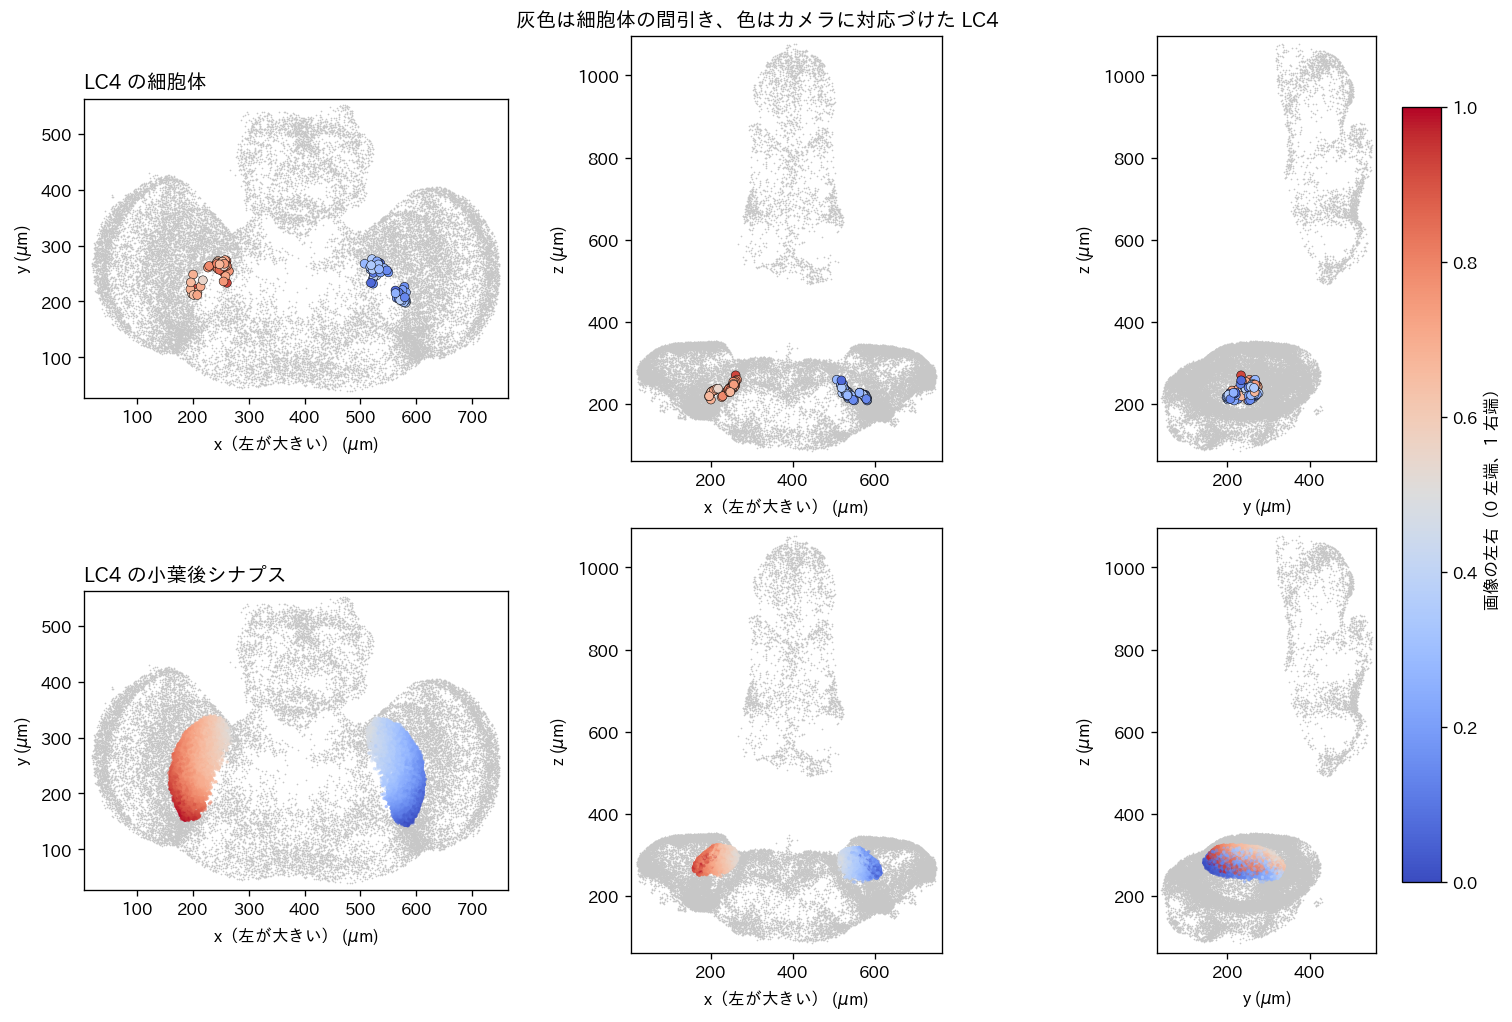

In [8]:
views = ((0, 1, "x（左が大きい）", "y"), (0, 2, "x（左が大きい）", "z"), (1, 2, "y", "z"))
limits = []
for i, j, _, _ in views:
    pad_i = 0.02 * (np.nanmax(soma[:, i]) - np.nanmin(soma[:, i]))
    pad_j = 0.02 * (np.nanmax(soma[:, j]) - np.nanmin(soma[:, j]))
    limits.append(
        (
            (np.nanmin(soma[:, i]) - pad_i, np.nanmax(soma[:, i]) + pad_i),
            (np.nanmin(soma[:, j]) - pad_j, np.nanmax(soma[:, j]) + pad_j),
        )
    )

norm = Normalize(vmin=0.0, vmax=1.0)
fig, axes = plt.subplots(2, 3, figsize=(12.5, 8.2), constrained_layout=True)
layers = (
    (cell_soma, cell_u, 28, 1.0, "LC4 の細胞体"),
    (syn_um[syn_take], u[syn_take], 4, 0.55, "LC4 の小葉後シナプス"),
)
for row, (pts, color, size, alpha, title) in enumerate(layers):
    for col, ((i, j, xl, yl), (xlim, ylim)) in enumerate(zip(views, limits)):
        ax = axes[row, col]
        ax.scatter(bg[:, i], bg[:, j], s=1, c="0.78", linewidths=0, rasterized=True)
        ax.scatter(
            pts[:, i],
            pts[:, j],
            s=size,
            c=color,
            cmap="coolwarm",
            norm=norm,
            alpha=alpha,
            linewidths=0.3 if row == 0 else 0,
            edgecolors="k" if row == 0 else "none",
            rasterized=True,
        )
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel(f"{xl} ($\\mu$m)")
        ax.set_ylabel(f"{yl} ($\\mu$m)")
        if col == 0:
            ax.set_title(title, loc="left")
cbar = fig.colorbar(
    ScalarMappable(norm=norm, cmap="coolwarm"),
    ax=axes,
    fraction=0.03,
    pad=0.02,
)
cbar.set_label("画像の左右（0 左端、1 右端）")
fig.suptitle("灰色は細胞体の間引き、色はカメラに対応づけた LC4", y=1.02)
plt.show()

## カメラ画面の上の位置

背景の色が、上の図と同じ左右の対応である。黒点は LC4 の 1 本ずつで、横位置が列 `a`、縦位置が列 `b` の平均である。点の平均は画面の縁まで届かない。1 本の樹状突起が何十列にもまたがるので、中心は端の列より内側に残る。

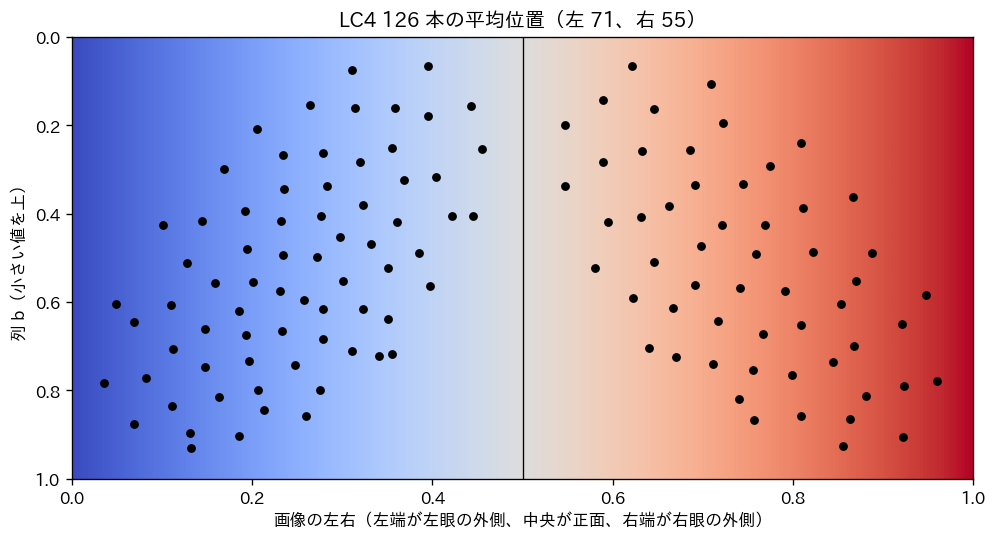

In [10]:
fig, ax = plt.subplots(figsize=(8.2, 4.4), constrained_layout=True)
gradient = np.linspace(0, 1, 256)[None, :]
ax.imshow(
    gradient,
    cmap="coolwarm",
    norm=norm,
    extent=(0, 1, 1, 0),
    aspect="auto",
    interpolation="bilinear",
)
ax.scatter(cell_u, cell_v, s=28, c="k", linewidths=0, zorder=3)
ax.axvline(0.5, color="k", lw=0.8)
ax.set_xlim(0, 1)
ax.set_ylim(1, 0)
ax.set_xlabel("画像の左右（左端が左眼の外側、中央が正面、右端が右眼の外側）")
ax.set_ylabel("列 b（小さい値を上）")
ax.set_title(f"LC4 {len(cell_id)} 本の平均位置（左 {int((cell_side == 0).sum())}、右 {int((cell_side == 1).sum())}）")
plt.show()

## 3D 空間から画面への対応

下の平面は、前のカメラ画面を小葉の手前に置いたものである。点は LC4 の 1 本で、小葉の後シナプスの平均位置にある。線の先は、その細胞の列番号 `a` と `b` から決めた画面上の位置である。x が大きい左眼は平面の青い半分へ、右眼は赤い半分へ落ちる。平面は見やすくするため z を 120 µm 下げてあり、光が集まる面ではない。

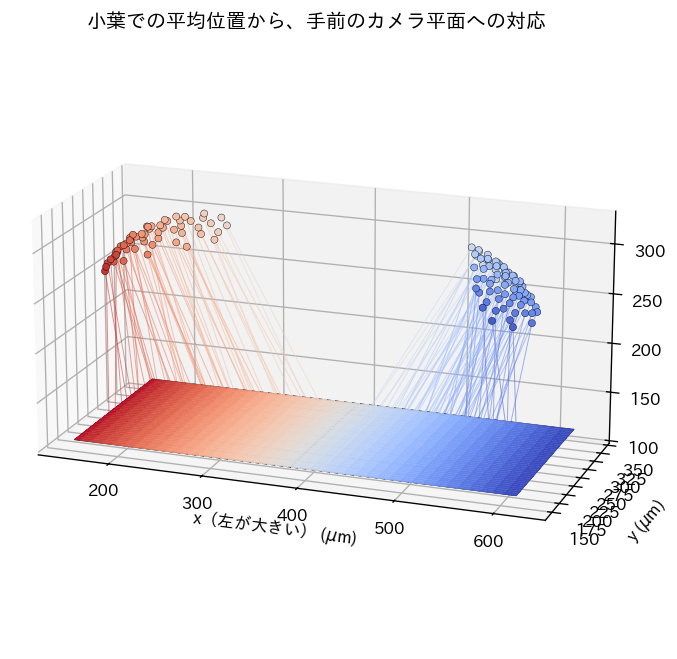

In [12]:
syn_s = syn_um[order]
cell_xyz = np.array([syn_s[g].mean(axis=0) for g in groups])

xmin, xmax = float(syn_um[:, 0].min()), float(syn_um[:, 0].max())
ymin, ymax = float(syn_um[:, 1].min()), float(syn_um[:, 1].max())
z_plane = float(syn_um[:, 2].min()) - 120.0
uu = np.linspace(0.0, 1.0, 80)
vv = np.linspace(0.0, 1.0, 40)
UU, VV = np.meshgrid(uu, vv)
# u = 0 is the image left, which is the left eye and the large-x side.
XX = xmax - UU * (xmax - xmin)
YY = ymax - VV * (ymax - ymin)
ZZ = np.full_like(XX, z_plane)
face = plt.cm.coolwarm(norm(UU))
face[..., 3] = 0.92

fig = plt.figure(figsize=(9.6, 6.6))
ax = fig.add_subplot(1, 1, 1, projection="3d")
for point, cu, cv in zip(cell_xyz, cell_u, cell_v):
    px = xmax - cu * (xmax - xmin)
    py = ymax - cv * (ymax - ymin)
    ax.plot(
        [point[0], px],
        [point[1], py],
        [point[2], z_plane],
        color=plt.cm.coolwarm(norm(cu)),
        lw=0.6,
        alpha=0.55,
    )
ax.scatter(
    cell_xyz[:, 0],
    cell_xyz[:, 1],
    cell_xyz[:, 2],
    s=18,
    c=cell_u,
    cmap="coolwarm",
    norm=norm,
    edgecolors="k",
    linewidths=0.25,
    depthshade=False,
)
ax.plot_surface(XX, YY, ZZ, facecolors=face, shade=False, linewidth=0, antialiased=False)
border_u = np.array([0.0, 1.0, 1.0, 0.0, 0.0])
border_v = np.array([0.0, 0.0, 1.0, 1.0, 0.0])
ax.plot(
    xmax - border_u * (xmax - xmin),
    ymax - border_v * (ymax - ymin),
    np.full(5, z_plane),
    color="k",
    lw=0.7,
)
ax.plot(
    [xmax - 0.5 * (xmax - xmin), xmax - 0.5 * (xmax - xmin)],
    [ymax, ymin],
    [z_plane, z_plane],
    color="k",
    lw=0.6,
)
ax.view_init(elev=18, azim=-70)
span = np.array([xmax - xmin, ymax - ymin, float(syn_um[:, 2].max()) - z_plane])
ax.set_box_aspect(span / span.max())
ax.set_xlabel("x（左が大きい） ($\\mu$m)")
ax.set_ylabel("y ($\\mu$m)")
ax.set_zlabel("z ($\\mu$m)")
ax.set_title("小葉での平均位置から、手前のカメラ平面への対応")
plt.show()

## 横の帯ごとに上下を引き伸ばした位置

画面の横を、片眼あたり 8 本の帯に切る。帯の中にある小葉の列について、`b` が最小の列をその帯の上端、最大の列を下端に合わせ、間を均等に伸ばす。淡い点は伸ばしたあとの列で、各帯は上から下まで埋まる。黒点は LC4 の 1 本で、平均の横位置が落ちる帯の同じ伸縮を、平均の縦位置にかけたものである。上下の絶対位置は使わない。左端の帯はもともと下寄りにしか列がないので、画像の上端はその帯でいちばん上の列になる。画面中央に近い帯は逆で、下端がいちばん下の列になる。角に黒点がなくても、その画素は端の列を持つ LC4 に対応する。黒点は平均の位置だからである。


bands 8 per eye  columns 1742  stretched v 0.06–0.99


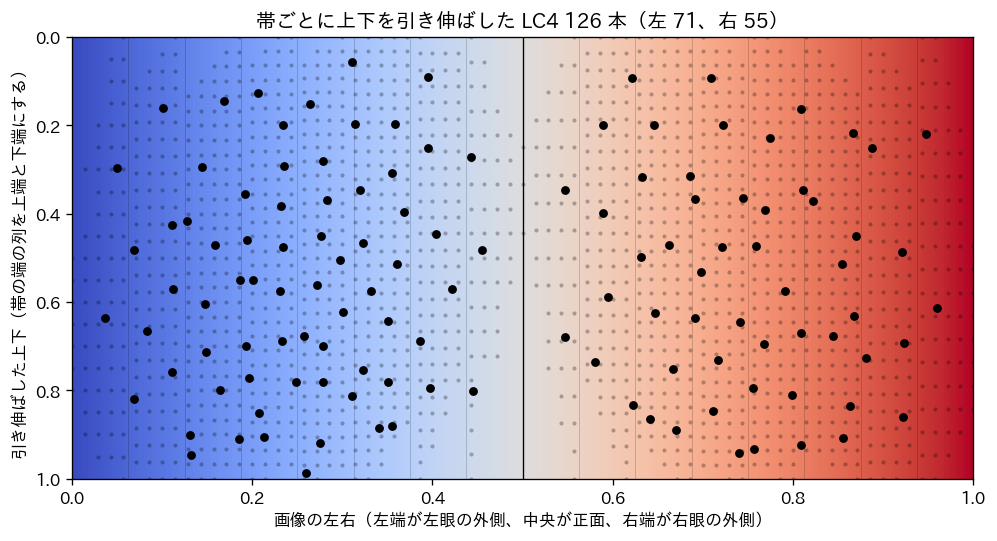

In [6]:
N_BINS = 8


def stretch_vertical(u_pts, v_pts, side_pts, n_bins=N_BINS):
    """帯の中の列の b の範囲を、その帯の画像の上端から下端へ均等に伸ばす。"""
    out = np.empty(len(v_pts), dtype=np.float64)
    for code, grid, u0, u1 in (
        (0, pack["left_ab"], 0.0, 0.5),
        (1, pack["right_ab"], 0.5, 1.0),
    ):
        valid = grid[:, 0] >= 0
        cu, cv = image_uv(
            grid[valid],
            np.full(int(valid.sum()), code, dtype=np.int8),
            pack["left_ab"],
            pack["right_ab"],
        )
        edges = np.linspace(u0, u1, n_bins + 1)
        col_bin = np.clip(np.digitize(cu, edges) - 1, 0, n_bins - 1)
        low = np.array([cv[col_bin == b].min() for b in range(n_bins)])
        high = np.array([cv[col_bin == b].max() for b in range(n_bins)])
        mask = side_pts == code
        pt_bin = np.clip(np.digitize(u_pts[mask], edges) - 1, 0, n_bins - 1)
        out[mask] = (v_pts[mask] - low[pt_bin]) / (high[pt_bin] - low[pt_bin])
    return out


col_u, col_v, col_side = [], [], []
for code, grid in ((0, pack["left_ab"]), (1, pack["right_ab"])):
    valid = grid[:, 0] >= 0
    uu, vv = image_uv(
        grid[valid],
        np.full(int(valid.sum()), code, dtype=np.int8),
        pack["left_ab"],
        pack["right_ab"],
    )
    col_u.append(uu)
    col_v.append(vv)
    col_side.append(np.full(int(valid.sum()), code, dtype=np.int8))
col_u = np.concatenate(col_u)
col_v = np.concatenate(col_v)
col_side = np.concatenate(col_side)
col_v_s = stretch_vertical(col_u, col_v, col_side)
cell_v_s = stretch_vertical(cell_u, cell_v, cell_side)
print(
    f"bands {N_BINS} per eye  "
    f"columns {len(col_u)}  "
    f"stretched v {cell_v_s.min():.2f}–{cell_v_s.max():.2f}"
)

fig, ax = plt.subplots(figsize=(8.2, 4.4), constrained_layout=True)
gradient = np.linspace(0, 1, 256)[None, :]
ax.imshow(
    gradient,
    cmap="coolwarm",
    norm=norm,
    extent=(0, 1, 1, 0),
    aspect="auto",
    interpolation="bilinear",
)
ax.scatter(col_u, col_v_s, s=6, c="k", alpha=0.28, linewidths=0, zorder=2, rasterized=True)
ax.scatter(cell_u, cell_v_s, s=28, c="k", linewidths=0, zorder=3)
ax.axvline(0.5, color="k", lw=0.8)
for u0, u1 in ((0.0, 0.5), (0.5, 1.0)):
    edges = np.linspace(u0, u1, N_BINS + 1)
    ax.vlines(edges[1:-1], 0, 1, colors="k", lw=0.35, alpha=0.28, zorder=2)
ax.set_xlim(0, 1)
ax.set_ylim(1, 0)
ax.set_xlabel("画像の左右（左端が左眼の外側、中央が正面、右端が右眼の外側）")
ax.set_ylabel("引き伸ばした上下（帯の端の列を上端と下端にする）")
ax.set_title(
    f"帯ごとに上下を引き伸ばした LC4 {len(cell_id)} 本"
    f"（左 {int((cell_side == 0).sum())}、右 {int((cell_side == 1).sum())}）"
)
plt.show()
